# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** ______________________________  
**Група:** ______________________________  
**Дата:** ______________________________

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
!pip install -q -U keras-tuner

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report
import keras_tuner as kt


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

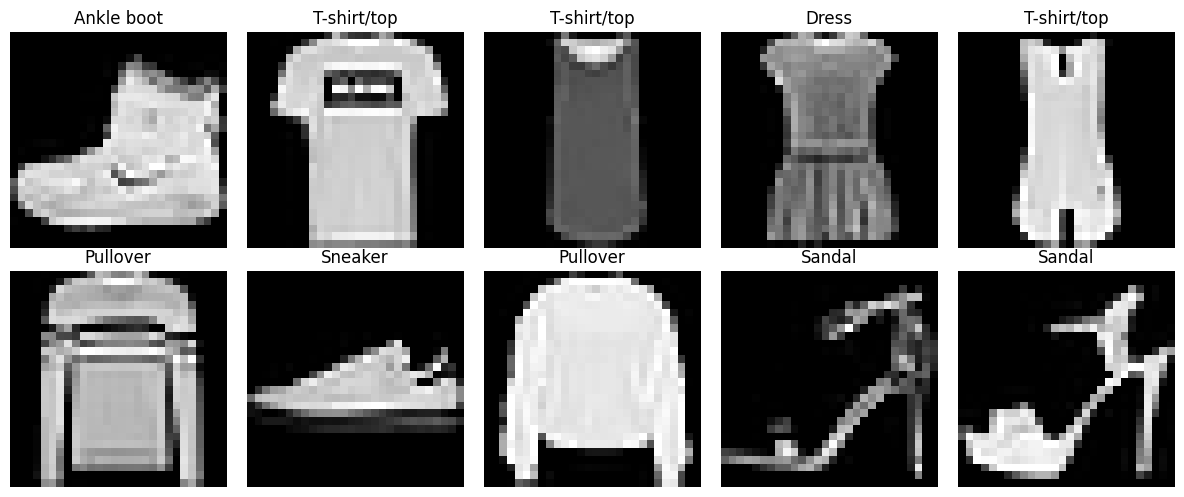

In [3]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("x_train dtype:", x_train.dtype, "| min:", x_train.min(), "| max:", x_train.max())
print("x_test dtype:", x_test.dtype, "| min:", x_test.min(), "| max:", x_test.max())

x_train dtype: float32 | min: 0.0 | max: 1.0
x_test dtype: float32 | min: 0.0 | max: 1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(10, activation="softmax")
])

optimizer = keras.optimizers.Adam(learning_rate=1e-3)

model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    x_train,
    y_train,
    epochs=30,
    batch_size=128,
    validation_split=0.15,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.7781 - loss: 0.6209 - val_accuracy: 0.8453 - val_loss: 0.4187 - learning_rate: 0.0010
Epoch 2/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8431 - loss: 0.4349 - val_accuracy: 0.8556 - val_loss: 0.3868 - learning_rate: 0.0010
Epoch 3/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8563 - loss: 0.3931 - val_accuracy: 0.8686 - val_loss: 0.3633 - learning_rate: 0.0010
Epoch 4/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8645 - loss: 0.3700 - val_accuracy: 0.8729 - val_loss: 0.3523 - learning_rate: 0.0010
Epoch 5/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8729 - loss: 0.3489 - val_accuracy: 0.8751 - val_loss: 0.3403 - learning_rate: 0.0010
Epoch 6/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8725 - loss: 0.3426 - val_accuracy: 0.8748 - val_loss: 0.3480 - learning_rate: 0.0010
Epoch 7/30
399/399 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8787 - loss: 0.330

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
model.save("fashion_mnist_model.keras")

### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

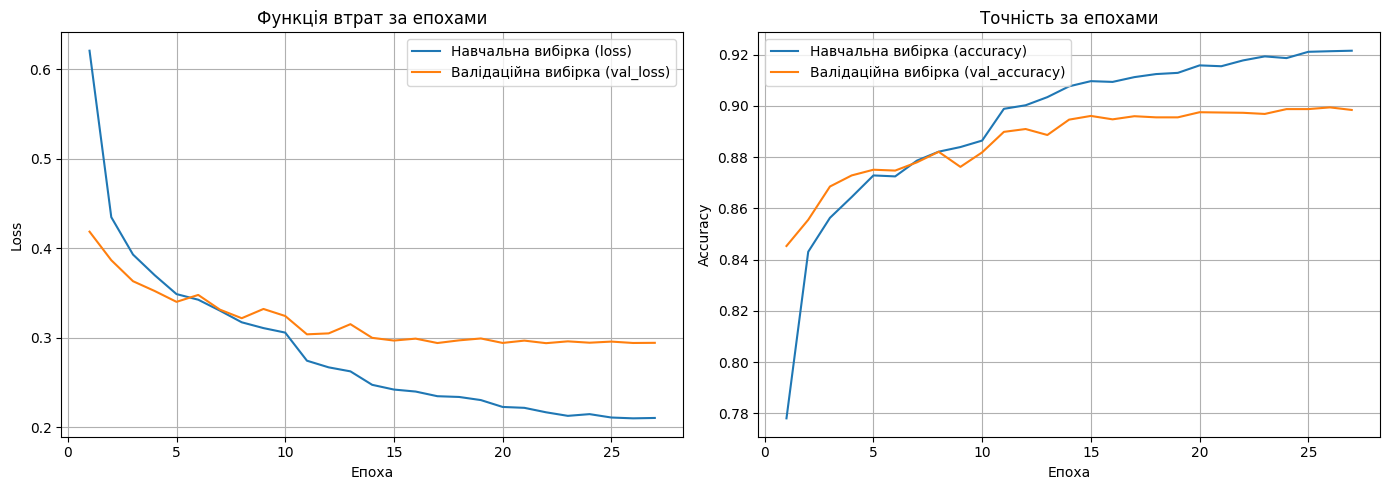

In [9]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
epochs = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, history.history["loss"], label="Навчальна вибірка (loss)")
plt.plot(epochs, history.history["val_loss"], label="Валідаційна вибірка (val_loss)")
plt.title("Функція втрат за епохами")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, history.history["accuracy"], label="Навчальна вибірка (accuracy)")
plt.plot(epochs, history.history["val_accuracy"], label="Валідаційна вибірка (val_accuracy)")
plt.title("Точність за епохами")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

if test_acc >= 0.87:
    print("Поріг точності 0.87 досягнуто.")
else:
    print("Поріг точності 0.87 не досягнуто.")

y_pred_probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Test loss: 0.3097
Test accuracy: 0.8926
Поріг точності 0.87 досягнуто.

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top     0.8348    0.8590    0.8467      1000
     Trouser     0.9878    0.9730    0.9804      1000
    Pullover     0.7994    0.8210    0.8101      1000
       Dress     0.8836    0.9030    0.8932      1000
        Coat     0.8139    0.8090    0.8114      1000
      Sandal     0.9757    0.9640    0.9698      1000
       Shirt     0.7388    0.6930    0.7152      1000
     Sneaker     0.9432    0.9640    0.9535      1000
         Bag     0.9781    0.9810    0.9795      1000
  Ankle boot     0.9667    0.9590    0.9629      1000

    accuracy                         0.8926     10000
   macro avg     0.8922    0.8926    0.8923     10000
weighted avg     0.8922    0.8926    0.8923     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

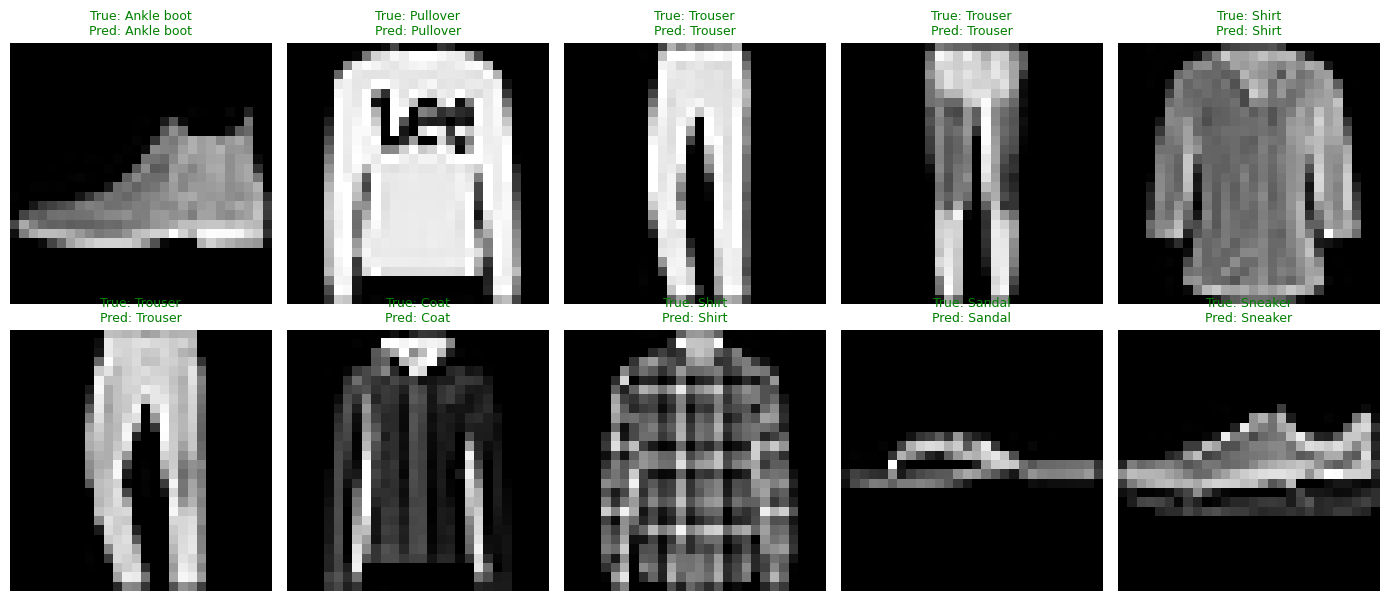

In [11]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
y_pred_probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

plt.figure(figsize=(14, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    true_label = class_names[y_test[i]]
    pred_label = class_names[y_pred[i]]
    is_correct = (y_test[i] == y_pred[i])
    color = "green" if is_correct else "red"
    plt.title(f"True: {true_label}\nPred: {pred_label}", color=color, fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
_..._

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip install -q -U keras-tuner

import keras_tuner as kt
from keras_tuner import RandomSearch
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [15]:
x_tr, x_val = x_train[:-10000], x_train[-10000:]
y_tr, y_val = y_train[:-10000], y_train[-10000:]

print("x_tr:", x_tr.shape, "y_tr:", y_tr.shape)
print("x_val:", x_val.shape, "y_val:", y_val.shape)
print("x_test:", x_test.shape, "y_test:", y_test.shape)

x_tr: (50000, 28, 28) y_tr: (50000,)
x_val: (10000, 28, 28) y_val: (10000,)
x_test: (10000, 28, 28) y_test: (10000,)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [16]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(28, 28)))
    model.add(layers.Flatten())

    num_layers = hp.Int("num_layers", min_value=1, max_value=3, step=1)
    l2_rate = hp.Choice("l2_rate", values=[1e-4, 1e-3, 1e-2])
    dropout_rate = hp.Float("dropout_rate", min_value=0.1, max_value=0.5, step=0.1)

    for i in range(num_layers):
        units = hp.Int(f"units_{i}", min_value=32, max_value=512, step=32)
        model.add(
            layers.Dense(
                units=units,
                activation="relu",
                kernel_regularizer=l2(l2_rate)
            )
        )
        model.add(layers.Dropout(rate=dropout_rate))

    model.add(layers.Dense(10, activation="softmax"))

    lr = hp.Choice("learning_rate", values=[0.01, 0.001, 0.0001])
    optimizer = keras.optimizers.Adam(learning_rate=lr)

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [17]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = RandomSearch(
    build_model,
    objective="val_accuracy",
    max_trials=3,
    executions_per_trial=1,
    directory="keras_tuner_dir",
    project_name="fashion_mnist_tuning",
    overwrite=True
)

tuner.search_space_summary()

Search space summary
Default search space size: 5
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
l2_rate (Choice)
{'default': 0.0001, 'conditions': [], 'values': [0.0001, 0.001, 0.01], 'ordered': True}
dropout_rate (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [18]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
from tensorflow.keras.callbacks import ReduceLROnPlateau

tuner_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

tuner_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=0
)

tuner.search(
    x_tr,
    y_tr,
    epochs=10,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[tuner_early_stop, tuner_reduce_lr],
    verbose=1
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі гіперпараметри:")
for key, value in best_hp.values.items():
    print(f"  {key}: {value}")

best_model = tuner.hypermodel.build(best_hp)
print("\nАрхітектура найкращої моделі:")
best_model.summary()

best_history = best_model.fit(
    x_tr,
    y_tr,
    epochs=20,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
    ],
    verbose=1
)

Trial 3 Complete [00h 00m 51s]
val_accuracy: 0.8241999745368958

Best val_accuracy So Far: 0.8496999740600586
Total elapsed time: 00h 01m 48s
Найкращі гіперпараметри:
  num_layers: 1
  l2_rate: 0.0001
  dropout_rate: 0.30000000000000004
  units_0: 32
  learning_rate: 0.01
  units_1: 288
  units_2: 224

Архітектура найкращої моделі:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7279 - loss: 0.7706 - val_accuracy: 0.8201 - val_loss: 0.5290 - learning_rate: 0.0100
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7747 - loss: 0.6526 - val_accuracy: 0.8253 - val_loss: 0.5306 - learning_rate: 0.0100
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7843 - loss: 0.6376 - val_accuracy: 0.8338 - val_loss: 0.5014 - learning_rate: 0.0100
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7876 - loss: 0.6254 - val_accuracy: 0.8285 - val_loss: 0.5232 - learning_rate: 0.0100
Epoch 5/20
375/391 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7918 - loss: 0.6225
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.004999999888241291.
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7895 - loss: 0.6285 - val_accuracy: 0.8306 - val_loss: 0.5288 - learning_rate: 0.0100
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8060 - loss: 0.5782 - va

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Best model test loss: 0.4416
Best model test accuracy: 0.8562


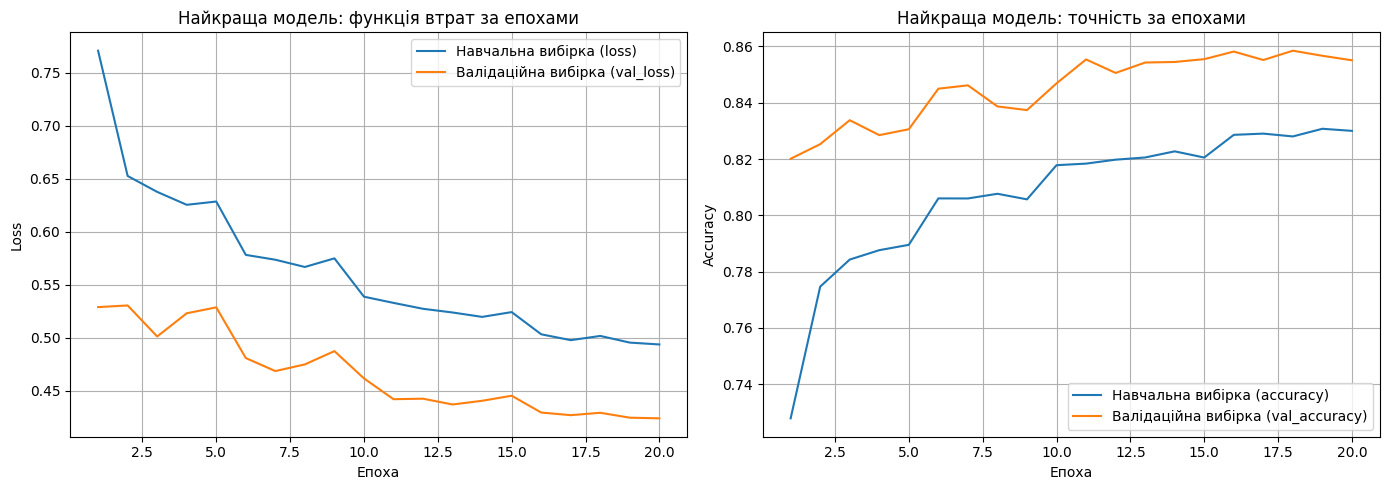

In [19]:
best_test_loss, best_test_acc = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Best model test loss: {best_test_loss:.4f}")
print(f"Best model test accuracy: {best_test_acc:.4f}")

best_epochs = range(1, len(best_history.history["loss"]) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(best_epochs, best_history.history["loss"], label="Навчальна вибірка (loss)")
plt.plot(best_epochs, best_history.history["val_loss"], label="Валідаційна вибірка (val_loss)")
plt.title("Найкраща модель: функція втрат за епохами")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(best_epochs, best_history.history["accuracy"], label="Навчальна вибірка (accuracy)")
plt.plot(best_epochs, best_history.history["val_accuracy"], label="Валідаційна вибірка (val_accuracy)")
plt.title("Найкраща модель: точність за епохами")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів |  |  |
| Кількість нейронів |  |  |
| Швидкість навчання |  |  |
| Точність на тестовій вибірці (accuracy) |  |  |
| Втрати на тестовій вибірці (loss) |  |  |
| Кількість епох навчання |  |  |

**У висновках дайте відповідь:**

Чи досягнуто точності не нижче 0,87 у завданні 1? Так, у завданні 1 досягнуто тестової точності вище мінімального порогу 0,87
Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці? Результат оптимізації гіперпараметрів залежить від випадкового вибору конфігурацій у RandomSearch (при 3 спробах він може як перевершити базову модель, так і показати близьку або трохи нижчу точність залежно від обраних шарів, нейронів і швидкості навчання)
Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками? Найкращими визнаються ті гіперпараметри (кількість прихованих шарів, кількість нейронів у шарах, learning rate, Dropout та L2-регуляризація), які дали найвищу валідаційну точність; відмінності між запусками пояснюються випадковою ініціалізацією ваг, перемішуванням/випадковим пошуком у RandomSearch, стохастичним градієнтним спуском та маскуванням нейронів у Dropout.
Які класи Fashion MNIST класифікувати найскладніше? Найскладніше класифікуються схожі за силуетом та яскравістю класи верхнього одягу — Shirt, T-shirt/top, Pullover і Coat, а також інколи Sneaker та Ankle boot.


---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.